# 小さな行列で学ぶ位相推定
## 逆QFT型QPE・iterative QPE・BPE・BPDEから、Kanno論文Fig. 1Cへ

**系1量子ビットの行列を使い、回路・測定・古典推定を一つずつ追う自習教材です。**
厳密な固有状態での成功例の後、初期状態を意図的にずらして比較します。
数式を読むだけでなく、回路の状態ベクトルから確率を計算し、その確率から模擬測定します。

### 学習目標と進め方

1. 位相を干渉で測定確率に変換する。
2. 逆QFT型QPEと、系を保持するiterative QPEの対応を理解する。
3. 毎回状態を準備し直すBPE・BPDEを実行し、初期状態と推定モデルの関係を調べる。
4. Fig. 1Bと1Cの測定の違い、全0測定の脱分極背景抑制を説明する。

目安は本編90〜120分＋Fig. 1Cへの接続30分です。初学者は2〜3回に分けて構いません。
必要な前提は複素数、内積、2×2行列、量子ビットの重ね合わせです。
各節で **予想 → 実行 → 数式と照合 → 演習** の順に進めてください。解答例は折り畳み表示です。

### 実行環境

Python 3.10以上、NumPy、Matplotlib、Qiskit、pylatexencを使います。
ローカルでは同梱のrequirements.txtで準備できます。Colabなどで不足する場合は、次のセルを有効にしてください。
このNotebook単体で実行でき、リポジトリの他のPythonファイル、IBMアカウント、QPU、Aerは不要です。
配布済み出力を読むだけでも進められます。乱数はセルごとの固定seedです。

**用語：逆FFTではなく逆QFT（Quantum Fourier Transform）です。**
ここでいうiterative QPEは半古典的逆QFT型を指します。
BPEは各ショットで系を再準備する教育用グリッドベイズ推定、BPDEはKanno論文Fig. 1Bの枝別準備回路です。
Wiebe–Granade法の粒子近似や、Kanno論文のGaussian更新・MPO最適化を再実装するものではありません。

In [1]:
# 必要な場合だけコメントを外して実行し、その後カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "matplotlib>=3.8,<4" "qiskit>=2.0,<3" "pylatexenc>=2.10,<3"

In [2]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
TAU = 2 * np.pi
ATOL = 1e-10

def draw(qc, fold=110):
    # 回路を画像で表示。数値計算にはこの描画関数は使わない。
    fig = qc.draw(output="mpl", fold=fold)
    display(fig)
    plt.close(fig)

def draw_measured(qc, qubits):
    # 描画用のコピーだけに測定を追加。厳密確率は測定前の回路から計算する。
    measured = qc.copy()
    readout = ClassicalRegister(len(qubits), "readout")
    measured.add_register(readout)
    measured.measure(qubits, readout)
    draw(measured)

def show_probs(probabilities, title, ax=None, shots=None, seed=123):
    p = np.asarray(probabilities, dtype=float)
    m = int(np.log2(len(p)))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3))
    x = np.arange(len(p))
    ax.bar(x, p, width=0.65, label="Exact probability", alpha=0.75)
    if shots:
        counts = np.random.default_rng(seed).multinomial(shots, p / p.sum())
        ax.plot(x, counts / shots, "ko", ms=4, label=f"{shots} simulated shots")
    ax.set_xticks(x, [format(i, f"0{m}b") for i in x], rotation=60 if m > 3 else 0)
    ax.set(xlabel="Measured bits (MSB ... LSB)", ylabel="Probability", title=title)
    ax.legend(fontsize=8)
    return ax

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__, "Qiskit:", qiskit.__version__)
print("以降のshot/countはすべてシミュレーションです。")

Python: 3.12.7
NumPy: 2.4.6 Matplotlib: 3.10.0 Qiskit: 2.4.1
以降のshot/countはすべてシミュレーションです。


## 0．共通の行列とビット順序

$$K=\begin{pmatrix}1/8&0\\0&3/8\end{pmatrix},\qquad
U=e^{2\pi iK},\qquad U|j\rangle=e^{2\pi i\phi_j}|j\rangle.$$

| 固有状態 | 位相 $\phi$ | 2進数3桁 |
|---|---:|---|
| $|0\rangle$ | $1/8$ | $0.001_2$ |
| $|1\rangle$ | $3/8$ | $0.011_2$ |

求める差は $\Delta=\phi_1-\phi_0=1/4=0.010_2$ です。
位相の単位は「1周」です。$\hbar=1$ として物理的時間発展 $e^{-iHt}$ を使う場合は
$\phi=-Et/(2\pi)\pmod 1$ となり、符号とエネルギー換算が必要です。本教材は符号を簡単にするため正符号の指数を使います。

Qiskitの状態ベクトルの並びは $|q_{n-1}\cdots q_0\rangle$ です。
QPEでは補助が $q_0,\ldots,q_{m-1}$、系が $q_m$。
表示する補助の文字列は $q_{m-1}\cdots q_0$ で、整数 $y$ は位相 $y/2^m$ に対応します。
後の2量子ビット回路では $q_0=a$（補助）、$q_1=s$（系）です。
数式では読みやすく $|a,s\rangle$ と書きますが、Qiskitの配列添字は $2s+a$ です。

In [3]:
PHASES = np.array([1/8, 3/8])
K = np.diag(PHASES)
GAP = PHASES[1] - PHASES[0]
zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)
psi_mixed = np.sqrt(0.75) * zero + np.sqrt(0.25) * one

def u_power(L, phases=PHASES):
    return np.diag(np.exp(1j * TAU * L * np.asarray(phases)))

def ry(theta):
    c, s = np.cos(theta/2), np.sin(theta/2)
    return np.array([[c, -s], [s, c]], dtype=complex)

print("K =\n", K)
print("U =\n", u_power(1))
for phi in PHASES:
    print(f"phi={phi:.3f} -> 0.{int(8*phi):03b}_2")
print("gap =", GAP)
assert np.allclose(u_power(1).conj().T @ u_power(1), np.eye(2))

K =
 [[0.125 0.   ]
 [0.    0.375]]
U =
 [[ 0.707107+0.707107j  0.      +0.j      ]
 [ 0.      +0.j       -0.707107+0.707107j]]
phi=0.125 -> 0.001_2
phi=0.375 -> 0.011_2
gap = 0.25


### 0.1 最初に区別する記号：桁番号・反復回数・時間

**$L$は位相の桁番号ではなく、基本操作$U$を何回適用するかを表す正の整数です。**
本教材では数式もPython引数も反復回数を`L`で統一します。以前の版ではこの量を$k$と書いていました。

| 記号 | 意味 | 例 |
|---|---|---|
| $m$ | 読み取る位相の2進数の桁数 | $m=3$なら$0.b_1b_2b_3$ |
| $b_j$ | 小数点から数えて第$j$桁の値（0または1） | $0.001_2$では$b_1=0,b_2=0,b_3=1$ |
| $r$ | べき$2^r$を選ぶ指数。0から数える | $r=0,1,2$ |
| $L$ | $U$の反復回数。位相を何倍にするか | $L=1,2,4$、あるいは3や5 |
| $\Delta t$ | 基本操作$U$一回に対応する時間 | 実時間への換算の基準 |
| $t$ | その測定設定での時間発展の長さ | $t=L\Delta t$ |

時間発展として書けば、
$$U=e^{-iH\Delta t}\quad\Longrightarrow\quad
U^L=e^{-iHL\Delta t}=e^{-iHt},\qquad t=L\Delta t.$$
本教材は$U=e^{+2\pi iK}$の符号で定義しているので、同じ式への対応は$K=-H\Delta t/(2\pi)$です。
$U|\phi\rangle=e^{2\pi i\phi}|\phi\rangle$に対しては
$$U^L|\phi\rangle=e^{2\pi iL\phi}|\phi\rangle.$$
すなわち、**反復回数を増やす＝発展時間を長くする＝蓄積位相を倍増させる**、という同じ操作を表しています。
$\Delta t$を変える場合は$U$そのものも変わります。このNotebookでは$U$を固定して$L$を変えます。

**方式ごとに違うのは、$L$の選び方と測定の使い方です。**

- 逆QFT型QPEでは、補助$q_r$に対して$L_r=2^r$を選びます。$r$は指数、$L_r$は回数であり、同じ量ではありません。
  逆QFTで情報をまとめてから出力ビットを読むので、$U^{2^r}$を制御する補助が、そのまま位相の「第$r$桁」を直接測っているわけではありません。
- iterative QPEでは、その同じ反復回数を順に使います。3桁なら$L=4,2,1$の順で、既知の下位ビットを補正しながら$b_3,b_2,b_1$を読みます。
- この教材のBPE/BPDEでは、$L$は各ショットの発展時間を選ぶ実験設定です。2のべきに限らず3や5も使え、一般に「第何桁の測定」という対応はありません。
- Kanno論文Fig. 1Cの$U_{\rm evol}^{t/\Delta t}$では、指数$t/\Delta t$がこの$L$に相当します。
  論文では基本操作を$U_{\rm evol}\approx e^{-iH\Delta t}$として短い回路で近似しています。

| べきの指数$r$ | 反復回数$L=2^r$ | 発展時間 | 3桁のiterative QPEで補正後に読むビット |
|---:|---:|---|---|
| 2 | 4 | $4\Delta t$ | $b_3$（末尾） |
| 1 | 2 | $2\Delta t$ | $b_2$ |
| 0 | 1 | $\Delta t$ | $b_1$（先頭） |

例えば$\phi=0.001_2$なら$4\phi=0.1_2$、$2\phi=0.01_2$、$\phi=0.001_2$です。
大きい反復回数で下位ビットを小数第1桁へ移し、既に読んだビットの影響を補正して、順に読みます。
multi-ancillaの逆QFTは、この関係を量子回路内の干渉でまとめて処理します。

**確認問題：** $\Delta t=0.1$の単位で$U^5$を使うと、$r=5$の測定または第5桁の測定でしょうか？

<details><summary>解答例</summary>

どちらでもありません。$L=5$回の反復、発展時間$t=0.5$を表します。
$L=5$は2の整数べきでないため、このQPEの$r$の設定列にはありませんが、BPE/BPDEの干渉測定には使えます。
本教材の固有位相$\phi=1/8$なら、蓄積位相は$L\phi=5/8$周です。
</details>

## 1．共通部品：干渉で位相を読む

補助を $|+\rangle$ にし、1の枝だけに $U^L$ を適用します。
系が固有状態 $|\phi\rangle$ なら
$$\frac{|0\rangle+|1\rangle}{\sqrt2}|\phi\rangle
\longrightarrow\frac{|0\rangle+e^{2\pi iL\phi}|1\rangle}{\sqrt2}|\phi\rangle.$$
補助に $P(\beta)=\operatorname{diag}(1,e^{i\beta})$ と最後のHadamardをかけると
$$P(a=0)=\frac{1+\cos(2\pi L\phi+\beta)}2.$$
候補値 $\epsilon$ を使う場合は $\beta=-2\pi L\epsilon$ と置きます。
この時のピークは $\epsilon=\phi\pmod{1/L}$。$L$ が大きいほど局所的に鋭くなる一方、候補の周期的な曖昧さも増えます。

**実行前の予想：** $\phi=1/8$ のとき、$L=1,2,4$ では区間 $[0,1)$ に何個のピークが見えるでしょうか。

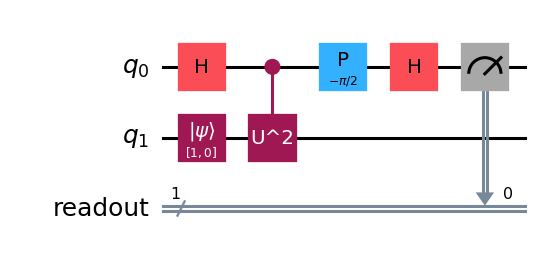

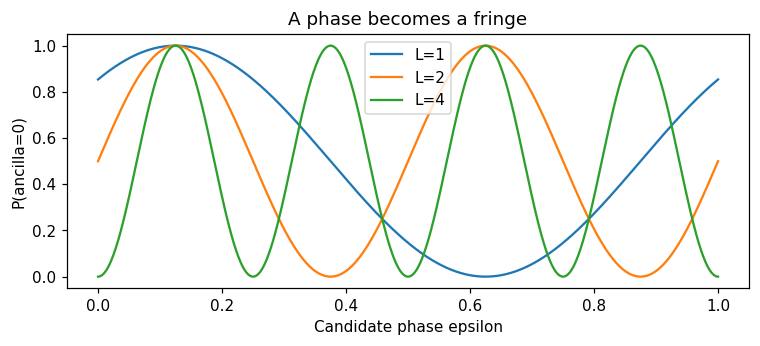

In [4]:
def ramsey_circuit(psi, L=1, beta=0.0):
    qc = QuantumCircuit(2)
    qc.initialize(psi, 1)
    qc.h(0)
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}").control(), [0, 1])
    qc.p(beta, 0)
    qc.h(0)
    return qc

def ancilla_zero(qc):
    return float(Statevector.from_instruction(qc).probabilities([0])[0])

def bpe_probability(weights, L, beta):
    # betaはスカラーでも配列でもよい。
    amplitude = np.dot(weights, np.exp(1j * TAU * L * PHASES))
    return 0.5 * (1 + np.real(np.exp(1j * beta) * amplitude))

draw_measured(ramsey_circuit(zero, L=2, beta=-TAU * 2 * PHASES[0]), [0])
eps = np.linspace(0, 1, 801)
fig, ax = plt.subplots(figsize=(8, 3))
for L in [1, 2, 4]:
    ax.plot(eps, bpe_probability([1, 0], L, -TAU*L*eps), label=f"L={L}")
    for e in [0.03, 0.125, 0.36]:
        actual = ancilla_zero(ramsey_circuit(zero, L, -TAU*L*e))
        assert np.isclose(actual, bpe_probability([1, 0], L, -TAU*L*e), atol=ATOL)
ax.set(xlabel="Candidate phase epsilon", ylabel="P(ancilla=0)", title="A phase becomes a fringe")
ax.legend(); plt.show()

### 演習1：ピークが出れば答えか？

上のセルの $L$ に8を追加してください。$\epsilon=\phi+1/L$ もピークになることを式で示し、
大きい $L$ の測定だけでは位相を一意に決められない理由を説明してください。

<details><summary>解答例</summary>

位相差が $2\pi L(\phi-\epsilon)$ なので、候補を $1/L$ 変えても余弦は同じです。
異なる $L$ や事前区間の情報を組み合わせる必要があります。
最後のHadamardの前は両枝の絶対値が等しいため、補助をZ測定するだけでは位相が読めないことも確認してください。
</details>

## 2．逆QFT型QPE：位相を3個の補助ビットへ

$m$ 個の補助にHadamardをかけ、補助 $q_r$ を制御として $U^{2^r}$ を適用します。
固有状態なら、逆QFT前の補助は
$$\frac1{\sqrt{2^m}}\sum_{x=0}^{2^m-1}e^{2\pi ix\phi}|x\rangle.$$
逆QFTの定義は
$$F^\dagger|x\rangle=\frac1{\sqrt{2^m}}\sum_y e^{-2\pi ixy/2^m}|y\rangle.$$
$\phi=y_0/2^m$ なら、幾何級数の和により出力は $|y_0\rangle$ になります。
以下では逆QFTをH・制御位相・SWAPで構成し、その行列が定義と一致することも確認します。

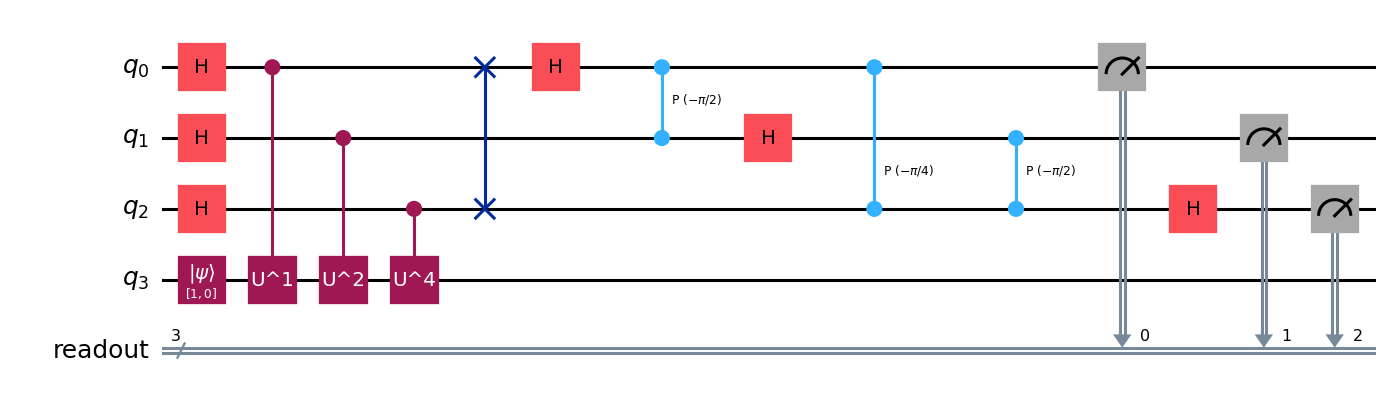

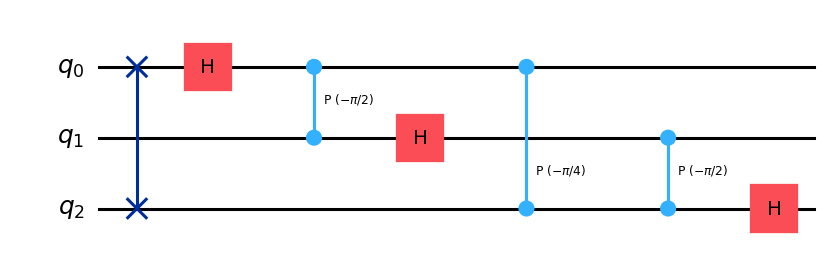

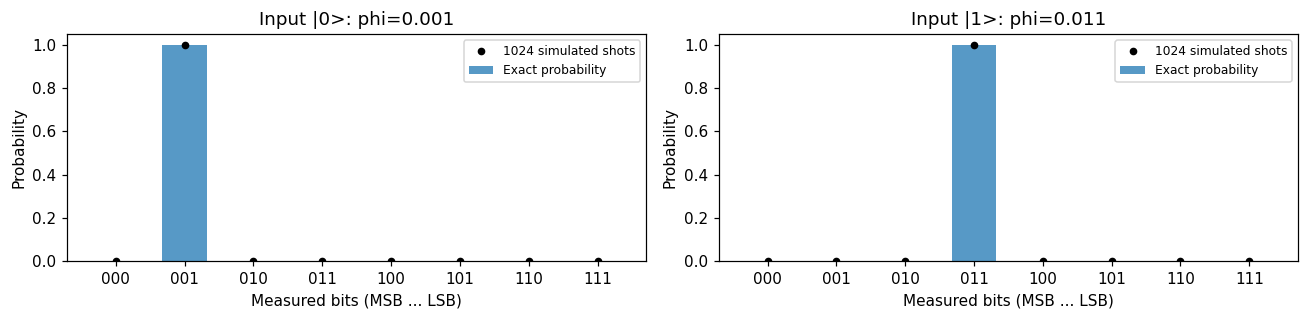

In [5]:
def inverse_qft(m):
    qc = QuantumCircuit(m, name="QFT_dg")
    for j in range(m // 2):
        qc.swap(j, m - 1 - j)
    for j in range(m):
        for ell in range(j):
            qc.cp(-np.pi / 2**(j - ell), j, ell)
        qc.h(j)
    return qc

def qpe_circuit(psi, m=3, phases=PHASES):
    qc = QuantumCircuit(m + 1)
    qc.initialize(psi, m)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(u_power(2**r, phases), label=f"U^{2**r}").control(), [r, m])
    qc.compose(inverse_qft(m), list(range(m)), inplace=True)
    return qc

def qpe_distribution(psi, m=3, phases=PHASES):
    state = Statevector.from_instruction(qpe_circuit(psi, m, phases))
    return state.probabilities(list(range(m)))

M = 8
x = np.arange(M)
fourier_dagger = np.exp(-1j * TAU * np.outer(x, x) / M) / np.sqrt(M)
assert np.allclose(Operator(inverse_qft(3)).data, fourier_dagger, atol=ATOL)
draw_measured(qpe_circuit(zero), [0, 1, 2])
draw(inverse_qft(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
show_probs(qpe_distribution(zero), "Input |0>: phi=0.001", axes[0], shots=1024)
show_probs(qpe_distribution(one), "Input |1>: phi=0.011", axes[1], shots=1024)
plt.tight_layout(); plt.show()
assert np.isclose(qpe_distribution(zero)[1], 1, atol=ATOL)
assert np.isclose(qpe_distribution(one)[3], 1, atol=ATOL)

### 2.1 近似状態を入れると何が出るか

入力を
$$|\psi\rangle=\sqrt{3/4}|0\rangle+\sqrt{1/4}|1\rangle$$
にします。線形性から、逆QFT後の全状態は
$$\sqrt{3/4}|001\rangle|0\rangle+\sqrt{1/4}|011\rangle|1\rangle.$$
したがって $P(001)=3/4,\ P(011)=1/4$。**固有位相の平均を出すのではありません。**
補助の測定結果で条件付けると、系も対応する固有状態になります。
これは位相がこの3ビット格子に載り、両位相を識別できる理想条件での説明です。
入力はコヒーレントな**純粋状態の重ね合わせ**です。密度行列の混合状態を入力しているわけではありません。
後の「成分が混ざった干渉信号」は、この純粋状態からも生じます。

ancilla=001, probability=0.750, system P(0),P(1)=[1. 0.]
ancilla=011, probability=0.250, system P(0),P(1)=[0. 1.]


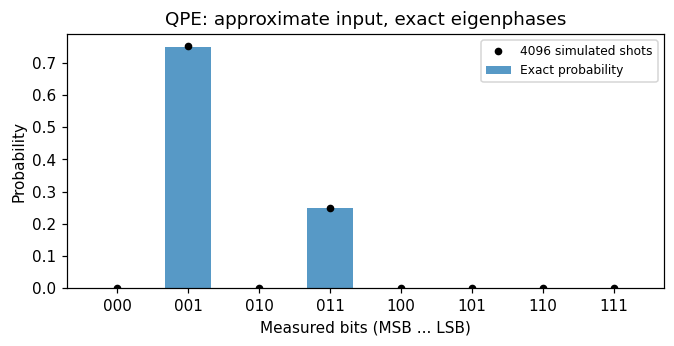

In [6]:
p_qpe = qpe_distribution(psi_mixed)
show_probs(p_qpe, "QPE: approximate input, exact eigenphases", shots=4096)
plt.show()
expected = np.zeros(8); expected[1] = 0.75; expected[3] = 0.25
assert np.allclose(p_qpe, expected, atol=ATOL)

# 配列添字は8*s+y。補助yを測ったときの系の条件付き状態を直接取り出す。
joint = Statevector.from_instruction(qpe_circuit(psi_mixed)).data.reshape(2, 8)
for y in [1, 3]:
    conditional = joint[:, y] / np.sqrt(p_qpe[y])
    print(f"ancilla={y:03b}, probability={p_qpe[y]:.3f}, system P(0),P(1)={abs(conditional)**2}")

### 演習2：成功確率と推定値の違い

入力の重みを $3/4\to1/4$ に交換し、ヒストグラムを再計算してください。
「基底の位相を得にくくなる」と「基底の位相そのものがずれる」は同じですか？

<details><summary>解答例</summary>

001の確率が1/4、011が3/4になります。出力される位相は変わりません。
目的状態との重なりが0なら、その固有位相を得ることはできません。
また、一般の位相は有限ビットで厳密に表せないので、これは全入力で無誤差という主張でもありません。
</details>

## 3．iterative QPE：補助1個でも系を保持すればよい

逆QFTの補助間の制御位相を、既に得た古典ビットによる位相補正へ置き換えます。
3桁なら **$U^4$で末尾のビット、$U^2$で次のビット、$U$で先頭のビット** を読みます。
補助は各ラウンドで測定・リセットしますが、**系は測定結果に応じて変わった状態をそのまま保持します。**

既に読んだ下位ビットを整数 $y_{\rm known}$ にまとめると、現在のべき $L=2^r$ に対する補正は
$$\beta=-2\pi L\frac{y_{\rm known}}{2^m}.$$
測定結果 $b\in\{0,1\}$ が得られたとき、系に作用するKraus演算子は
$$M_b=\frac{I+(-1)^b e^{i\beta}U^L}{2},\qquad
p_b=\|M_b|\psi\rangle\|^2,\qquad
|\psi_b\rangle=\frac{M_b|\psi\rangle}{\sqrt{p_b}}.$$
この式で全測定分岐を計算すれば、動的回路対応のシミュレータなしに理想分布を得られます。
下の動的回路は実際にH・制御U・古典条件付きP・測定・resetを含みます。
数値実行はKraus式で行い、回路図だけをStatevectorへ渡すことはしません。

round  repetitions L  observed (time order)  branch probability  system P(0),P(1)
(1, 4, '1', 0.9999999999999999, array([0.75, 0.25]))
(2, 2, '10', 0.7500000000000002, array([1., 0.]))
(2, 2, '11', 0.25000000000000006, array([0., 1.]))
(3, 1, '100', 0.7500000000000002, array([1., 0.]))
(3, 1, '110', 0.25000000000000006, array([0., 1.]))
QPEとiterative QPEの分布は一致: True


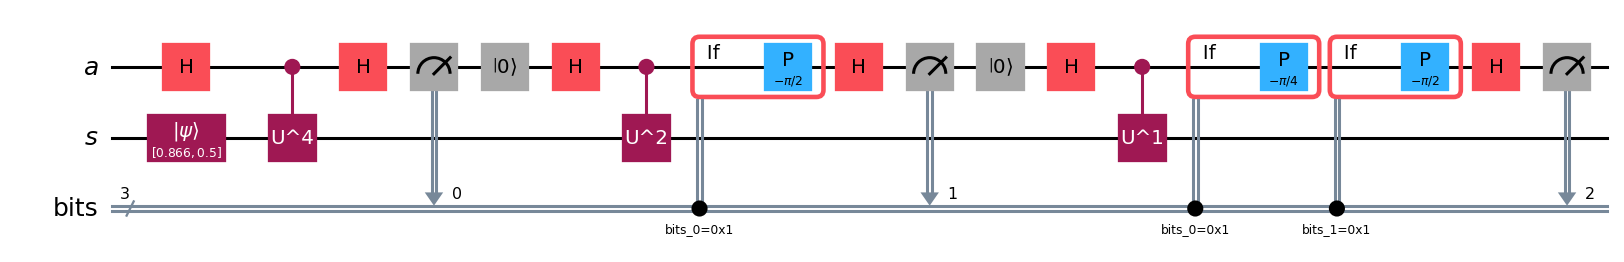

In [7]:
def iqpe_dynamic_circuit(m=3):
    a = QuantumRegister(1, "a")
    s = QuantumRegister(1, "s")
    c = ClassicalRegister(m, "bits")
    qc = QuantumCircuit(a, s, c)
    qc.initialize(psi_mixed, s[0])
    for ell, r in enumerate(reversed(range(m))):
        L = 2**r
        if ell:
            qc.reset(a[0])
        qc.h(a[0])
        qc.append(UnitaryGate(u_power(L), label=f"U^{L}").control(), [a[0], s[0]])
        for old in range(ell):
            angle = -TAU * L * 2**old / 2**m
            with qc.if_test((c[old], 1)):
                qc.p(angle, a[0])
        qc.h(a[0])
        qc.measure(a[0], c[ell])
    return qc

def iqpe_tree(psi, m=3, phases=PHASES, reprepare=False):
    # (既知の整数, 分岐確率, 条件付き系状態, 測定履歴)
    branches = [(0, 1.0, np.array(psi, complex), "")]
    trace = []
    for ell, r in enumerate(reversed(range(m))):
        next_branches = []
        L = 2**r
        for y, weight, conditional, history in branches:
            incoming = np.array(psi, complex) if reprepare else conditional
            beta = -TAU * L * y / 2**m
            for b in [0, 1]:
                out = (incoming + (-1)**b * np.exp(1j*beta) * (u_power(L, phases) @ incoming)) / 2
                probability = float(np.vdot(out, out).real)
                if probability < 1e-14:
                    continue
                state = out / np.sqrt(probability)
                new_y = y + b * 2**ell
                new_history = history + str(b)  # 時間順。最終表示のビット順とは逆。
                next_branches.append((new_y, weight*probability, state, new_history))
                trace.append((ell+1, L, new_history, weight*probability, abs(state)**2))
        branches = next_branches
    distribution = np.zeros(2**m)
    for y, weight, _, _ in branches:
        distribution[y] += weight
    return distribution, trace

draw(iqpe_dynamic_circuit(), fold=95)
p_iqpe, trace = iqpe_tree(psi_mixed)
print("round  repetitions L  observed (time order)  branch probability  system P(0),P(1)")
for row in trace:
    print(row)
assert np.allclose(p_iqpe, p_qpe, atol=ATOL)
print("QPEとiterative QPEの分布は一致:", np.allclose(p_iqpe, p_qpe))

正しいIQPE: [0.   0.75 0.   0.25 0.   0.   0.   0.  ]
毎ビット再準備: [0.      0.65625 0.      0.15625 0.      0.09375 0.      0.09375]


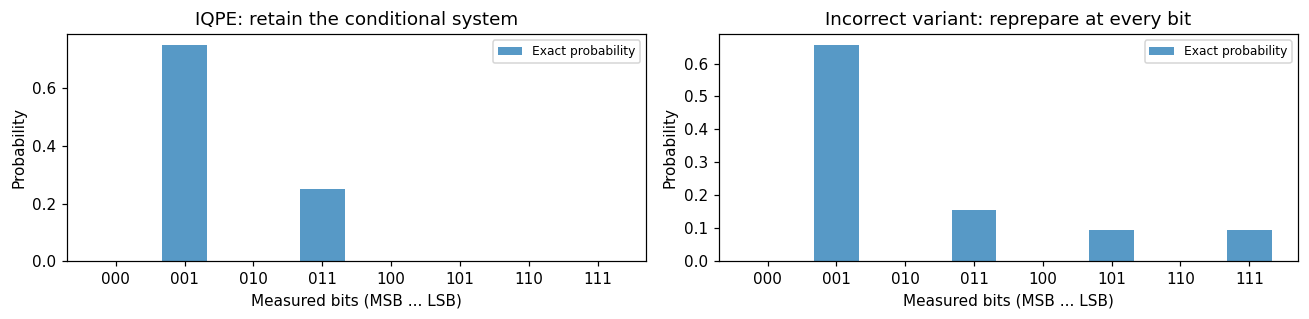

In [8]:
p_reset, _ = iqpe_tree(psi_mixed, reprepare=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
show_probs(p_iqpe, "IQPE: retain the conditional system", axes[0])
show_probs(p_reset, "Incorrect variant: reprepare at every bit", axes[1])
plt.tight_layout(); plt.show()
print("正しいIQPE:", p_iqpe)
print("毎ビット再準備:", p_reset)
assert not np.allclose(p_reset, p_qpe, atol=ATOL)

### 演習3：1ビットずつでも射影が起きるのはなぜ？

1. 測定履歴は時間順に表示しています。履歴110は最終的にどのビット列ですか？
2. 最初の $U^4$ の測定では、系の2成分を区別できますか？
3. 系を毎回再準備する変種で、元の固有位相以外の出力が現れる理由を説明してください。

<details><summary>解答例</summary>

1. 下位ビットから読んでいるので011です。
2. 両位相とも末尾が1なので区別できません。次のビットで区別されます。
3. 過去の測定で条件付けた系を捨てると、フィードバックで使う過去のビットと、新たな系の固有成分が一致しなくなります。
   独立に準備した状態から得たビットをつなぐだけでは、単一の位相測定になりません。
   固有状態入力なら再準備しても同じ固有状態なので、この差は見えません。
</details>

## 4．BPE：1回ごとの干渉測定をベイズ推定に渡す

この節では各ショットで系を同じ状態に準備し直します。
位相のグリッド $\phi\in[0,1)$ 上に事前分布を置き、
設定 $(L,\beta)$ で $R$ 回中 $n_0$ 回の補助0を観測したら
$$p(\phi\mid D)\propto p(\phi)\,
P_0(\phi;L,\beta)^{n_0}[1-P_0(\phi;L,\beta)]^{R-n_0},$$
$$P_0(\phi;L,\beta)=\frac{1+\cos(2\pi L\phi+\beta)}2$$
として更新します。二項係数は $\phi$ に依存しないため正規化で消えます。
ここで $\phi$ は推定する未知パラメータ、$\beta$（またはそれを決める $\epsilon$）は実験で設定する既知のノブです。

以下は事前に固定した設定列による、教育用の**グリッドベイズ推定**です。
適応的な測定設定選択、Gaussian近似、Wiebe–Granade法の効率的更新は使いません。
まず正しい単一固有状態で動作を確認し、その後、同じ単一位相モデルに近似状態のデータを渡します。

{'MAP': 0.1251220703125, 'mean': 0.125065933047741, 'equal_tail_95': (0.12446990022904277, 0.12536096862115295)}
 L   beta/pi  shots  observed n0  exact P0
 1     0.00    256          211    0.8536
 1    -0.50    256          227    0.8536
 2     0.00    256          119    0.5000
 2    -0.50    256          256    1.0000
 4     0.00    256            0    0.0000
 4    -0.50    256          131    0.5000
 8     0.00    256          256    1.0000
 8    -0.50    256          126    0.5000
16     0.00    256          256    1.0000
16    -0.50    256          128    0.5000
32     0.00    256          256    1.0000
32    -0.50    256          131    0.5000
各設定の模擬shot数: 256 総shot数: 3072
総controlled-U換算使用回数: 32256


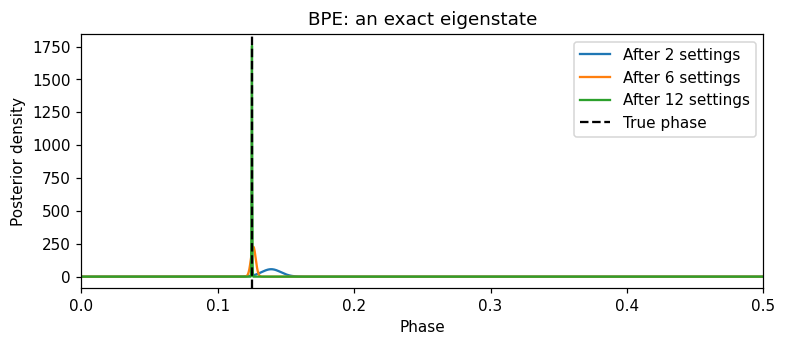

In [9]:
GRID = (np.arange(4096) + 0.5) / 4096  # 周期の端点を重複させない

def single_phase_model(phi, L, beta):
    return 0.5 * (1 + np.cos(TAU*L*phi + beta))

def bayes_update(grid, settings, true_probability, shots=256, seed=20261108):
    rng = np.random.default_rng(seed)
    logpost = np.zeros_like(grid)
    posteriors, data = [], []
    for L, beta in settings:
        true_p = float(np.clip(true_probability(L, beta), 0, 1))
        n0 = int(rng.binomial(shots, true_p))
        model_p = np.clip(single_phase_model(grid, L, beta), 1e-12, 1-1e-12)
        logpost += n0*np.log(model_p) + (shots-n0)*np.log1p(-model_p)
        logpost -= np.max(logpost)
        post = np.exp(logpost); post /= post.sum()
        posteriors.append(post)
        data.append((L, beta, shots, n0, true_p))
    return np.array(posteriors), data

def posterior_summary(grid, p):
    cdf = np.cumsum(p)
    lo, hi = np.interp([0.025, 0.975], cdf, grid)
    return {"MAP": float(grid[np.argmax(p)]), "mean": float(p @ grid),
            "equal_tail_95": (float(lo), float(hi))}

settings = [(L, beta) for L in [1, 2, 4, 8, 16, 32] for beta in [0.0, -np.pi/2]]
post_exact, data_exact = bayes_update(
    GRID, settings, lambda L,b: bpe_probability([1, 0], L, b))

fig, ax = plt.subplots(figsize=(8, 3))
for i in [1, 5, 11]:
    ax.plot(GRID, post_exact[i] * len(GRID), label=f"After {i+1} settings")
ax.axvline(PHASES[0], color="black", ls="--", label="True phase")
ax.set(xlim=(0, 0.5), xlabel="Phase", ylabel="Posterior density", title="BPE: an exact eigenstate")
ax.legend(); plt.show()
print(posterior_summary(GRID, post_exact[-1]))
print(" L   beta/pi  shots  observed n0  exact P0")
for L, beta, R, n0, p0 in data_exact:
    print(f"{L:2d} {beta/np.pi:8.2f} {R:6d} {n0:12d} {p0:9.4f}")
print("各設定の模擬shot数:", 256, "総shot数:", len(settings)*256)
print("総controlled-U換算使用回数:", 256*sum(L for L, _ in settings))

### 4.1 BPE/BPDEで時間を延ばす意味：感度と周期の交換条件

基本操作$U$を固定すると、$L$は各ショットの発展時間$t=L\Delta t$を設定します。
BPEでは「発展しない枝」と「する枝」の間に$-Et$、BPDEでは2状態の枝の間に$-(E_e-E_g)t$の相対位相が蓄積します。
候補値との差が$\delta\omega$なら、残る位相差は$\delta\theta=\delta\omega t$です。
短時間では近い値同士の確率がほとんど同じですが、長時間ではその違いを拡大して読めます。

Notebookの位相単位では、$\delta\phi=0.001$の違いは$L=1$で$2\pi\times0.001=0.00628$ rad、
$L=32$で$0.201$ radに拡大されます。**$L$は桁の指定ではなく、測定感度を変える設定です。**
単一位相が正しいモデルで、確率が位相に敏感な設定の局所的な統計誤差は概ね
$$\sigma_\phi\simeq\frac{1}{2\pi L\sqrt R},\qquad
\sigma_\omega\simeq\frac{1}{t\sqrt R}$$
と振る舞います。これは未知の位相候補を一意に選べた場合の感度の目安であり、多峰性まで解消する式ではありません。

**$L=1$だけでも原理的に推定できます。** $\beta=0$と$-\pi/2$のように余弦と正弦の両方を調べれば、
位相を1周期の範囲内で識別できます。多数のshotsを使えば精度も改善しますが、局所誤差の改善は概ね$1/\sqrt R$です。
$\beta=0$だけでは、さらに$\phi$と$1-\phi$の対称性が残ります。

他方、固定した$L>1$では、**どんな補正位相$\beta$を使っても**
$$P_0(\phi;L,\beta)=P_0(\phi+j/L;L,\beta),\qquad j\in\mathbb Z$$
なので、区間$[0,1)$に$L$個の区別できない候補が残ります。
例えば$L=32$だけでは、shotsを無限に増やしても$1/32$間隔の候補を区別できません。
一般に複数の整数$L$の最大公約数が$d$なら、$1/d$周期の同じ曖昧さが残ります。
$L=1$を含む短時間の測定で大まかな候補を選び、段階的に長時間の測定を追加して細かく読むのが、この節の設計です。

実際のエネルギーへ戻すと、固定した基本時間$\Delta t$と整数$L$だけでは、全体としても$2\pi/\Delta t$周期の曖昧さがあります。
本教材は最初から位相の基本区間$[0,1)$を選んでおり、エネルギーの広い範囲を無条件に識別するわけではありません。

### 4.2 実験：同じ総ショット数で3つの時間設定を比較する

ここでは初期状態を厳密な固有状態とし、時間選択の効果と初期状態の誤差を分けます。
各段階で2種類の補正位相を256 shotsずつ測り、6段階、合計3,072 shotsを使います。
補正位相は$\pi/5$と$\pi/5-\pi/2$で、既知のオフセットを加えた余弦・正弦の組です。
測定結果の確率が常に0や1になる特殊な設定を避けています。

| 計画 | 各段階の反復回数$L$ | 狙い |
|---|---|---|
| L=1 only | 1,1,1,1,1,1 | 短時間の測定を繰り返す |
| Staged L | 1,2,4,8,16,32 | 短時間で大まかに、長時間で細かく読む |
| L=32 only | 32,32,32,32,32,32 | 長時間だけでは候補が複数残ることを確認 |

総shotsは同じですが、総$U$換算反復回数$\sum R L$、すなわち総発展時間$\Delta t\sum R L$は違います。
**長時間の計画が、同じ計算資源で無条件に優れるという比較ではありません。** 状態準備の回数は揃え、発展の長さを変える比較です。
計画は事前に固定しており、結果に応じて次の$L$を適応的に選ぶ実装ではありません。

実行後は、上段の全位相範囲と下段の真値近傍を見比べてください。
幅の図は**全事後分布の等裾95%区間幅**です。複数ピークが残る場合、ピーク間の低確率領域も含む広い区間になります。
真値を使った拡大図・誤差・RMSEは、答えが既知のシミュレーションで推定を評価するための表示です。
RMSEは64回の独立した模擬実験のMAP誤差から計算します。表の`interval coverage`はその64回で95%区間が真値を含んだ割合で、
有限回の実験で0.95に必ず一致するわけではなく、信用区間一般の頻度的被覆保証を主張するものでもありません。

BPE: target=0.125, 256 shots/setting, 64 Monte Carlo trials
Plan          total shots  sum(R*L)  MAP        global 95% width  MAP error
L=1 only            3072      3072 0.125687          0.011041 +0.000687
Staged L            3072     32256 0.125443          0.000753 +0.000443
L=32 only           3072     98304 0.468704          0.937604 +0.343704
Repeated-experiment accuracy (first two identifiable plans):
Plan          circular RMSE  median global 95% width  interval coverage
L=1 only      0.003313                  0.011278              0.938
Staged L      0.000208                  0.000746              0.906
L=32 only: posterior mass in one alias cell around truth = 0.0312499999999993
L=32 only: min/max mass per 1/32-period cell = 0.031249999999991777 0.03125000000000937
L= 1: P(phi=0.137)=0.540795, P(phi+1/32)=0.442791
L=32: P(phi=0.137)=0.002524, P(phi+1/32)=0.002524


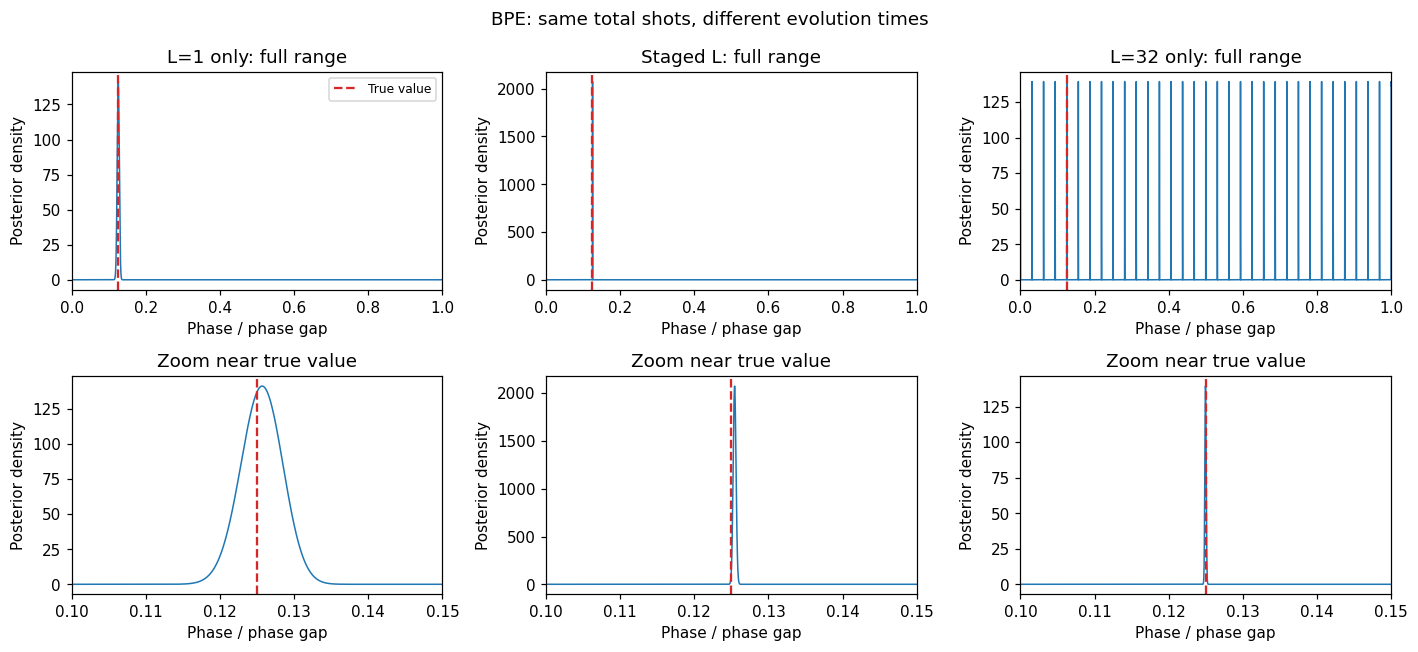

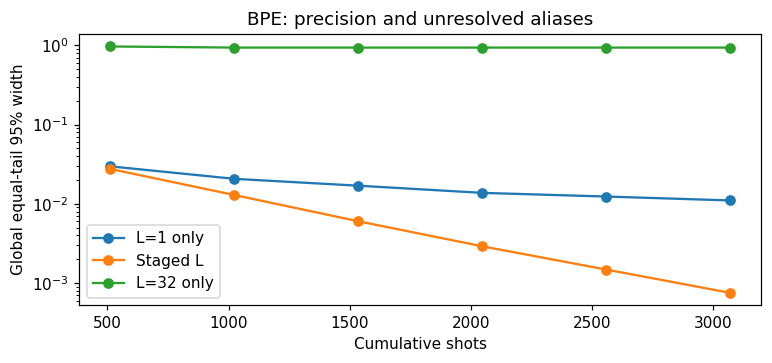

In [10]:
# 比較用は細かいグリッドを使い、長時間測定の狭いピークも解像する。
TIME_GRID = (np.arange(32768) + 0.5) / 32768
TIME_PLANS = {
    "L=1 only": [1, 1, 1, 1, 1, 1],
    "Staged L": [1, 2, 4, 8, 16, 32],
    "L=32 only": [32, 32, 32, 32, 32, 32],
}
TIME_BETAS = [np.pi/5, np.pi/5-np.pi/2]

def circular_error(estimate, target):
    return (np.asarray(estimate)-target+0.5) % 1 - 0.5

def compare_time_plans(true_probability, target, label, seed, shots=256, trials=64):
    grid = TIME_GRID
    results = {}
    print(f"{label}: target={target}, {shots} shots/setting, {trials} Monte Carlo trials")
    print("Plan          total shots  sum(R*L)  MAP        global 95% width  MAP error")
    for index, (name, lengths) in enumerate(TIME_PLANS.items()):
        plan = [(L, beta) for L in lengths for beta in TIME_BETAS]
        history, records = bayes_update(grid, plan, true_probability, shots=shots, seed=seed+index)
        summary = posterior_summary(grid, history[-1])
        widths = np.array([np.diff(posterior_summary(grid, p)["equal_tail_95"])[0]
                           for p in history[1::2]])
        results[name] = {"history": history, "records": records, "widths": widths,
                         "settings": plan, "summary": summary}
        error = circular_error(summary["MAP"], target)
        print(f"{name:13} {len(plan)*shots:10d} {shots*sum(L for L,b in plan):9d} "
              f"{summary['MAP']:.6f} {widths[-1]:17.6f} {error:+.6f}")

    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    for column, (name, result) in enumerate(results.items()):
        density = result["history"][-1] * len(grid)
        for row in [0, 1]:
            ax = axes[row, column]
            ax.plot(grid, density, lw=1)
            ax.axvline(target, color="C3", ls="--", label="True value")
            ax.set(xlabel="Phase / phase gap", ylabel="Posterior density")
        axes[0, column].set(xlim=(0, 1), title=name + ": full range")
        axes[1, column].set(xlim=(target-0.025, target+0.025), title="Zoom near true value")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(label + ": same total shots, different evolution times", fontsize=12)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(8, 3.2))
    cumulative_shots = 2*shots*np.arange(1, 7)
    for name, result in results.items():
        ax.semilogy(cumulative_shots, result["widths"], "o-", label=name)
    ax.set(xlabel="Cumulative shots", ylabel="Global equal-tail 95% width",
           title=label + ": precision and unresolved aliases")
    ax.legend(); plt.show()

    # 独立な模擬データを何組も生成し、1回の乱数例に依存しない精度を確認する。
    # ベイズ更新と同じ二項尤度を、行列積でまとめて評価する。
    print("Repeated-experiment accuracy (first two identifiable plans):")
    print("Plan          circular RMSE  median global 95% width  interval coverage")
    for index, name in enumerate(["L=1 only", "Staged L"]):
        plan = results[name]["settings"]
        probabilities = np.array([true_probability(L, beta) for L, beta in plan])
        rng = np.random.default_rng(seed + 100 + index)
        n0 = rng.binomial(shots, np.clip(probabilities, 0, 1), size=(trials, len(plan)))
        model = np.array([np.clip(single_phase_model(grid, L, beta), 1e-12, 1-1e-12)
                          for L, beta in plan])
        logpost = n0 @ np.log(model) + (shots-n0) @ np.log1p(-model)
        logpost -= logpost.max(axis=1, keepdims=True)
        posts = np.exp(logpost); posts /= posts.sum(axis=1, keepdims=True)
        estimates = grid[np.argmax(posts, axis=1)]
        intervals = np.array([posterior_summary(grid, p)["equal_tail_95"] for p in posts])
        rmse = np.sqrt(np.mean(circular_error(estimates, target)**2))
        coverage = np.mean((intervals[:, 0] <= target) & (target <= intervals[:, 1]))
        results[name]["rmse"] = float(rmse)
        print(f"{name:13} {rmse:.6f} {np.median(intervals[:,1]-intervals[:,0]):25.6f} {coverage:18.3f}")

    # L=32の周期性は、shotsや乱数では破れない。全32周期の確率質量を確認。
    long_post = results["L=32 only"]["history"][-1]
    mass_per_period = long_post.reshape(32, -1).sum(axis=1)
    assert np.allclose(mass_per_period, 1/32, atol=1e-9)
    near_true = np.abs(circular_error(grid, target)) < 1/64
    print("L=32 only: posterior mass in one alias cell around truth =", long_post[near_true].sum())
    print("L=32 only: min/max mass per 1/32-period cell =", mass_per_period.min(), mass_per_period.max())
    for L, beta in [(1, TIME_BETAS[0]), (32, TIME_BETAS[0])]:
        p = single_phase_model(0.137, L, beta)
        alias = single_phase_model(0.137+1/32, L, beta)
        print(f"L={L:2}: P(phi=0.137)={p:.6f}, P(phi+1/32)={alias:.6f}")
    return results

# BPE: 厳密な |0> 入力。モデルと真の確率が一致する条件。
time_bpe = compare_time_plans(
    lambda L,b: bpe_probability([1, 0], L, b), PHASES[0], "BPE", seed=510)

### 演習4A：狭いピークと一意な推定を区別する

1. L=1 onlyでshotsを256→1024に変えると、RMSEや区間幅はどう変わりますか？
2. L=32 onlyでは真値の近くに鋭いピークがあります。それだけで高精度に推定できたと言えますか？
3. L=32 onlyの真値近傍1周期分の事後確率が、shotsを増やしても約1/32なのはなぜですか？
4. Staged Lを[2,4,8,16,32,64]に変更すると、どんな曖昧さが残りますか？
   試す場合はTIME_PLANSのStaged Lだけを変更し、この比較セルを再実行してください。

<details><summary>解答例</summary>

1. 正しいモデルで十分なshotsなら、局所誤差は概ね半分になります。実測のRMSEは有限回の模擬実験なので多少揺らぎます。
2. 言えません。区間[0,1)に同じ高さの候補が32個あり、どの候補かを識別できていません。
3. すべてのデータの尤度が1/32周期で、事前分布も一様だからです。局所的に狭くなっても32候補の相対確率は変わりません。
   この多峰分布のMAPを単一の答えとして表示することは適切ではなく、表のMAPは代表する1点にすぎません。
4. すべてのLが偶数なので、位相が1/2異なる2候補を区別できません。
   ここまでの比較でStaged Lが一意に推定できたのは、L=1の測定を含むためです。
   本例の真値が周期の境界に近い場合、通常の平均や等裾区間では円周上の分布をうまく表せないことにも注意してください。

総shotsを揃えた比較の総$U$換算反復回数は、順に3,072、32,256、98,304です。
発展時間も揃えて比較するなら、例えばL=1 onlyの各設定を2,688 shotsにすると、Staged Lの256 shots/設定と総反復回数が揃います。
状態準備回数はこの場合には一致しないため、何を資源として揃えたかを明記することが大切です。
長い発展のノイズや近似誤差は、この理想的な比較には含まれていません。
</details>

### 4.3 ショット誤差を消しても、入力状態による混合は残る

入力が $|\psi\rangle=\sum_jc_j|\phi_j\rangle$ なら、実際の確率は
$$P_{\rm true}(0)=\frac12\left[1+\sum_j|c_j|^2\cos(2\pi L\phi_j+\beta)\right].$$
これは単一の固有位相の余弦とは異なります。
本例の $L=1,\ \beta=-2\pi\epsilon$ に対するピークは
$$\epsilon_{\rm peak}=\frac{\arg\left(\tfrac34 e^{2\pi i/8}+\tfrac14e^{6\pi i/8}\right)}{2\pi}
\simeq0.1762,$$
であり、固有位相0.125でも0.375でもありません。
以下の曲線はショットを一切使わない厳密確率です。曲線と回路計算も照合します。

exact fringe peak: 0.17620819117478337


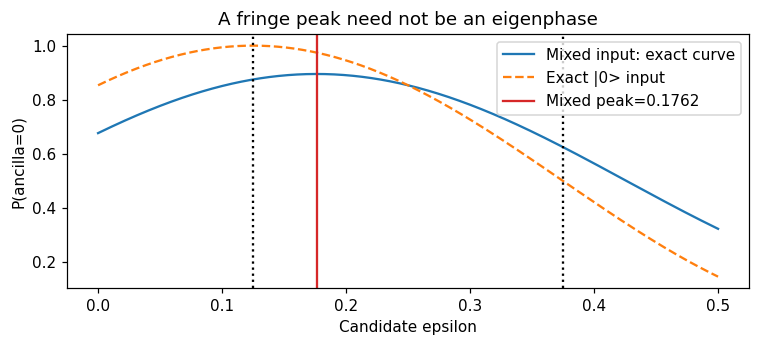

In [11]:
candidate = np.linspace(0, 0.5, 1001)
weights = abs(psi_mixed)**2
amplitude = np.dot(weights, np.exp(1j*TAU*PHASES))
peak_a = np.angle(amplitude) / TAU

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(candidate, bpe_probability(weights, 1, -TAU*candidate), label="Mixed input: exact curve")
ax.plot(candidate, bpe_probability([1, 0], 1, -TAU*candidate), "--", label="Exact |0> input")
ax.axvline(peak_a, color="C3", label=f"Mixed peak={peak_a:.4f}")
for phi in PHASES:
    ax.axvline(phi, color="black", ls=":")
ax.set(xlabel="Candidate epsilon", ylabel="P(ancilla=0)", title="A fringe peak need not be an eigenphase")
ax.legend(); plt.show()
print("exact fringe peak:", peak_a)
for e in [0.03, peak_a, 0.4]:
    assert np.isclose(ancilla_zero(ramsey_circuit(psi_mixed, 1, -TAU*e)),
                      bpe_probability(weights, 1, -TAU*e), atol=ATOL)

### 4.4 単一位相モデルへ混合データを渡す

まず $L=1$ で多数の補正位相を測定します。その後、複数の $L$ を使います。
比較するのは **事後分布の幅** と **測定確率の予測の適合** です。
幅が小さいだけではモデルが正しいことを意味しません。

注意：単一の曲線のピーク、ベイズ事後分布のMAP、全設定を通じた推定値は同じ定義ではありません。
単一位相の当てはめ結果は測定設定・shot数・事前分布に依存します。
「複数成分の入力なら常に0.1762へ収束する」という意味ではありません。
干渉振幅の低下も単一固有状態モデルでは表現できないため、MAPが確率曲線のピークからさらにずれる場合もあります。
表示する信用区間はグリッド上の等裾区間です。この例は周期の境界から離れていますが、一般には円周上の位相としての区間や多峰性にも注意が必要です。

L=1 only {'MAP': 0.1856689453125, 'mean': 0.185692748254772, 'equal_tail_95': (0.1847731261556235, 0.18635988893180952)}
several L {'MAP': 0.1270751953125, 'mean': 0.12573628016201643, 'equal_tail_95': (0.12269221034631803, 0.12717788550022946)}
Held-out probability RMSE: 0.13646401454107648


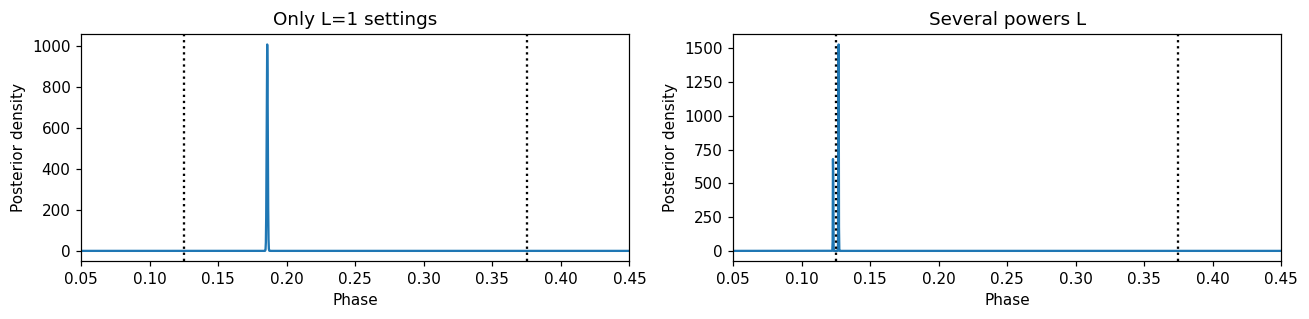

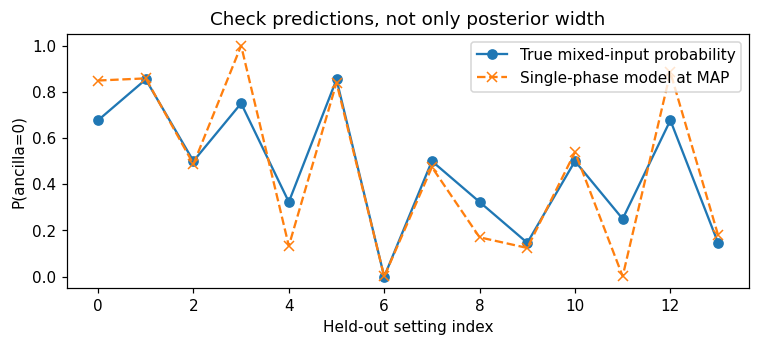

In [12]:
scan_settings = [(1, -TAU*e) for e in np.linspace(0, 1, 24, endpoint=False)]
post_scan, data_scan = bayes_update(
    GRID, scan_settings, lambda L,b: bpe_probability(weights, L, b), shots=2048, seed=81)
post_mixed, data_mixed = bayes_update(
    GRID, settings, lambda L,b: bpe_probability(weights, L, b), seed=82)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, post, title in zip(axes, [post_scan[-1], post_mixed[-1]],
                           ["Only L=1 settings", "Several powers L"]):
    ax.plot(GRID, post * len(GRID))
    for phi in PHASES:
        ax.axvline(phi, color="black", ls=":")
    ax.set(xlim=(0.05, 0.45), xlabel="Phase", ylabel="Posterior density", title=title)
plt.tight_layout(); plt.show()
for name, post in [("L=1 only", post_scan[-1]), ("several L", post_mixed[-1])]:
    print(name, posterior_summary(GRID, post))

# 推定で使っていない補正位相・べきも含む予測診断。
map_phase = posterior_summary(GRID, post_mixed[-1])["MAP"]
check_settings = [(L, beta) for L in range(1, 8) for beta in [0, -np.pi/2]]
truth = np.array([bpe_probability(weights, L, b) for L, b in check_settings])
prediction = np.array([single_phase_model(map_phase, L, b) for L, b in check_settings])
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(truth, "o-", label="True mixed-input probability")
ax.plot(prediction, "x--", label="Single-phase model at MAP")
ax.set(xlabel="Held-out setting index", ylabel="P(ancilla=0)", title="Check predictions, not only posterior width")
ax.legend(); plt.show()
print("Held-out probability RMSE:", np.sqrt(np.mean((truth-prediction)**2)))

### 演習4：shot数を増やせば何が改善するか

1. `shots`を256から4096へ増やし、厳密状態と近似状態で比較してください。
2. 「信用区間が狭いのに、予測確率が合わない」は矛盾ですか？
3. 複数固有値を含むモデルで推定する余地はありますか？

<details><summary>解答例</summary>

shot数を増やすと測定の統計誤差は減りますが、混合した干渉信号が単一位相になるわけではありません。
信用区間は仮定したモデル・事前分布の下での不確かさです。モデルの不一致全体を表しません。
固有値と重みの複数成分モデルで十分なデータを解析する方法は考えられますが、同定可能性・必要時間・資源を別途検討する必要があります。
本教材のBPEもKanno論文のGaussian更新も、その複数成分同時推定を実装していません。
なお、ベイズ推定でも同じ系を保持しながら逐次測定する方式は別の条件です。
「ベイズ推定一般は非射影」と一括りにせず、ここでの再準備と単一位相モデルの条件に注意してください。
</details>

## 5．BPDE：2本の枝の位相差を読む（Fig. 1B）

QPE/BPEは「時間発展しない枝」と「する枝」を比べます。
BPDEは
$$\frac{|0\rangle|g\rangle+|1\rangle|e\rangle}{\sqrt2}$$
を準備して、**両方の系の枝に制御なしの $U^L$** を適用します。
固有状態なら枝間の位相差は $2\pi L(\phi_e-\phi_g)$ です。
枝別の逆準備で系を両方とも0へ戻し、$P(\beta)$ とHを経て
$$P_B(a=0)=\frac{1+\cos(2\pi L\Delta+\beta)}2$$
を得ます。制御が不要になるのは時間発展であり、状態準備・逆準備の制御は残ります。

ここでは $U_g=I$ とし、励起側を
$$U_e=R_y(2\arccos\sqrt\eta),\qquad
U_e|0\rangle=\sqrt\eta|0\rangle+\sqrt{1-\eta}|1\rangle$$
と完全に指定します。$\eta=0$ が厳密な励起状態、$\eta=1/4$ が忠実度3/4の例です。
`W_B`は初期Hと枝別準備を含みます。`W_B.inverse()`は枝別逆準備と最後のHを含みます。

{'MAP': 0.2503662109375, 'mean': 0.25044138807883815, 'equal_tail_95': (0.24989032960399835, 0.2507905665726762)}


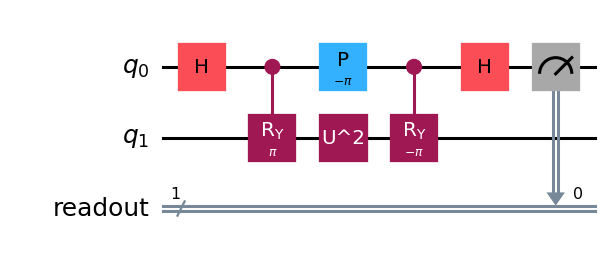

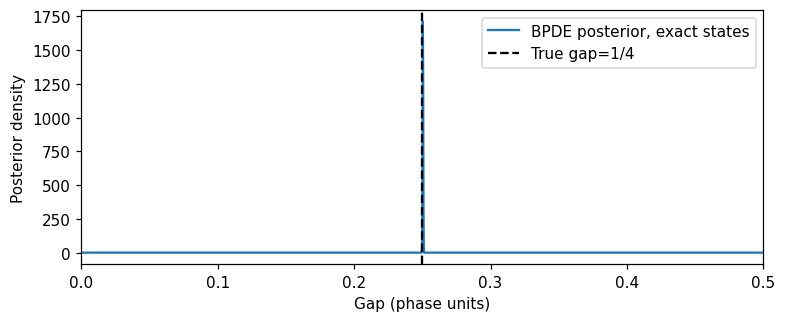

In [13]:
def preparation_b(eta=0.0):
    qc = QuantumCircuit(2, name="W_B")  # q0=a, q1=s
    qc.h(0)
    qc.cry(2*np.arccos(np.sqrt(eta)), 0, 1)
    return qc

def bpde_circuit(eta=0.0, L=1, beta=0.0):
    prep = preparation_b(eta)
    qc = QuantumCircuit(2)
    qc.compose(prep, inplace=True)
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}"), [1])
    qc.p(beta, 0)
    qc.compose(prep.inverse(), inplace=True)
    return qc

def bpde_probability(eta, L, beta):
    return 0.5*(1 + eta*np.cos(beta) + (1-eta)*np.cos(TAU*L*GAP+beta))

draw_measured(bpde_circuit(eta=0, L=2, beta=-TAU*2*GAP), [0])
for eta in [0, 0.25, 0.7]:
    for L in [1, 2, 5]:
        for beta in [0.0, 0.31, -1.7]:
            assert np.isclose(ancilla_zero(bpde_circuit(eta, L, beta)),
                              bpde_probability(eta, L, beta), atol=ATOL)

post_gap, data_gap = bayes_update(GRID, settings,
                                 lambda L,b: bpde_probability(0, L, b), seed=83)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(GRID, post_gap[-1]*len(GRID), label="BPDE posterior, exact states")
ax.axvline(GAP, color="black", ls="--", label="True gap=1/4")
ax.set(xlim=(0, 0.5), xlabel="Gap (phase units)", ylabel="Posterior density")
ax.legend(); plt.show()
print(posterior_summary(GRID, post_gap[-1]))

### 5.1 BPDEでも、L=1固定と段階的な長時間化を比較する

BPEと全く同じ計画・shots・位相グリッドを使います。
変えるのは、データを生成する回路の測定確率と、未知パラメータが位相差$\Delta$であることです。
基底・励起状態はともに厳密として、長時間の効果を初期状態の誤差から切り離します。
この条件ではBPEと同じ単一位相の尤度を使えます。

下の実行例は、先ほど回路と照合した`bpde_probability(eta=0, ...)`から模擬測定を生成します。
L=1 onlyでも$\Delta$を推定できます。Staged Lでは同じshotsでも局所的に細かく読めます。
L=32 onlyでは、位相差についても1/32間隔の32候補が残ります。
物理単位に直すと、位相差$\Delta$は$-(E_e-E_g)\Delta t/(2\pi)$に対応するため、
固定した時間$t$におけるギャップの周期は$2\pi/t$です。

BPDE: target=0.25, 256 shots/setting, 64 Monte Carlo trials
Plan          total shots  sum(R*L)  MAP        global 95% width  MAP error
L=1 only            3072      3072 0.249069          0.011291 -0.000931
Staged L            3072     32256 0.250320          0.000735 +0.000320
L=32 only           3072     98304 0.218613          0.968589 -0.031387
Repeated-experiment accuracy (first two identifiable plans):
Plan          circular RMSE  median global 95% width  interval coverage
L=1 only      0.002755                  0.011245              0.938
Staged L      0.000210                  0.000748              0.938
L=32 only: posterior mass in one alias cell around truth = 0.03125000000000297
L=32 only: min/max mass per 1/32-period cell = 0.0312499999999826 0.03125000000001246
L= 1: P(phi=0.137)=0.540795, P(phi+1/32)=0.442791
L=32: P(phi=0.137)=0.002524, P(phi+1/32)=0.002524
BPDE circuit, L=1: P(gap=1/4)=0.206107, P(gap=1/4+1/32)=0.132839
BPDE circuit, L=32: P(gap=1/4)=0.904508, P(gap=1/

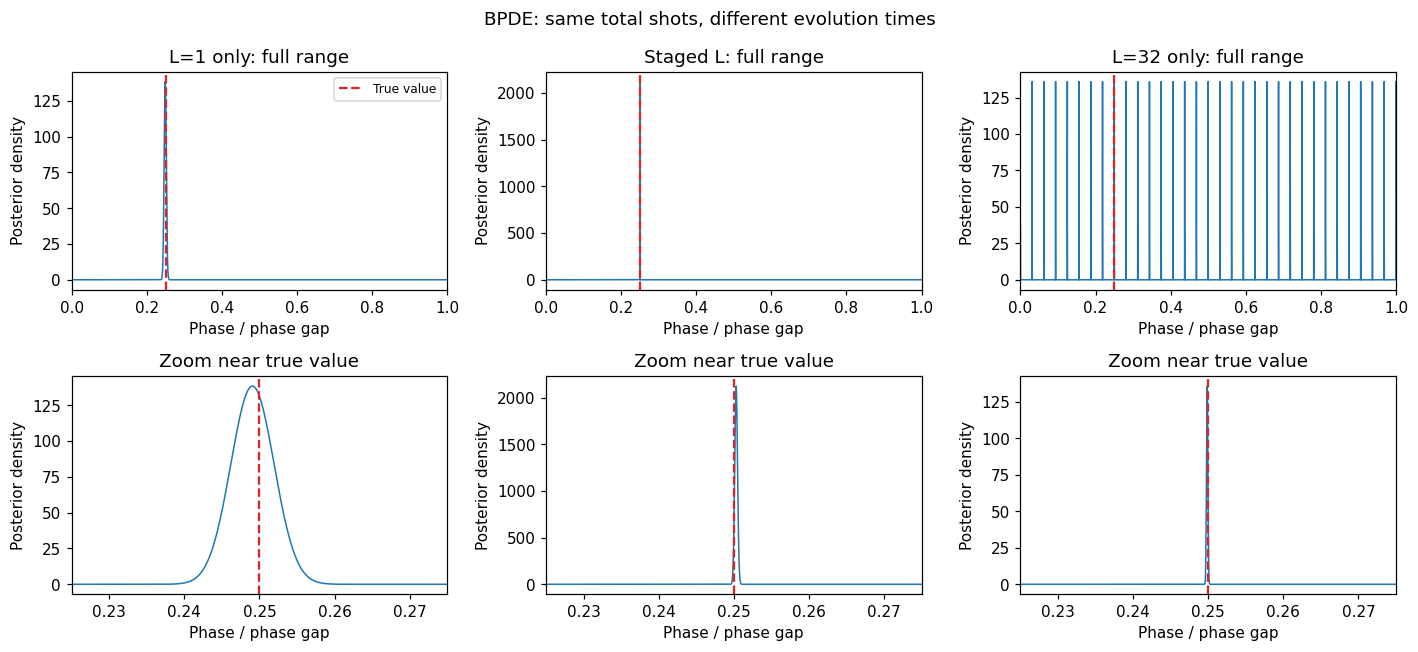

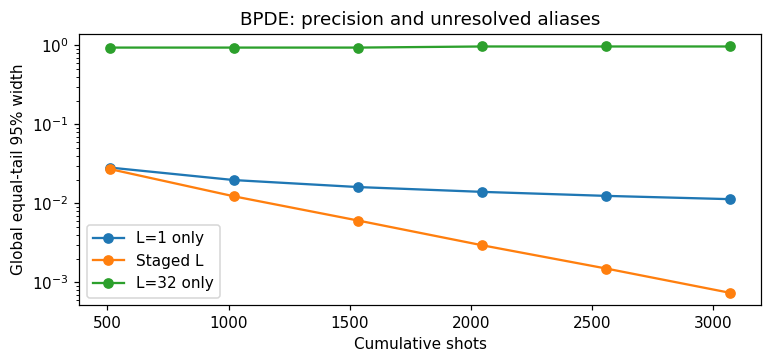

In [14]:
time_bpde = compare_time_plans(
    lambda L,b: bpde_probability(0, L, b), GAP, "BPDE", seed=610)

# 長時間だけでは同じになる別ギャップも、実際の2ビット回路で照合する。
# 基底位相を固定し、励起位相を1/32だけ変えた別の行列を用意する。
alternate_phases = PHASES + np.array([0.0, 1/32])
for L in [1, 32]:
    beta = TIME_BETAS[0]
    original = ancilla_zero(bpde_circuit(eta=0, L=L, beta=beta))
    alternate = QuantumCircuit(2)
    prep = preparation_b(0)
    alternate.compose(prep, inplace=True)
    alternate.append(UnitaryGate(u_power(L, alternate_phases)), [1])
    alternate.p(beta, 0)
    alternate.compose(prep.inverse(), inplace=True)
    alternative = ancilla_zero(alternate)
    print(f"BPDE circuit, L={L}: P(gap=1/4)={original:.6f}, "
          f"P(gap=1/4+1/32)={alternative:.6f}")
    if L == 32:
        assert np.isclose(original, alternative, atol=ATOL)
    else:
        assert not np.isclose(original, alternative, atol=ATOL)

### 演習5A：BPDEの「時間」と「差」

1. 同じ発展時間$t$でギャップが$\delta E$だけ違うと、枝間の位相差はどれだけ変わりますか？
2. L=32だけのBPDEでは、1/4と1/4+1/32の位相差を、補正位相を変えて区別できますか？
3. 時間を長くすることで、近似状態に由来する別の固有成分の寄与も必ず取り除けますか？

<details><summary>解答例</summary>

1. $\delta E\,t$ rad（符号は枝の順序による）変わります。これがギャップへの感度を高める理由です。
2. できません。両候補の蓄積位相の差が$2\pi$なので、どの補正位相でも同じ確率です。
   別の短い時間のデータか、1周期より狭く候補を選べる事前情報が必要です。
3. 保証されません。長時間化は感度を高める操作であり、各ショットで準備し直す近似状態を純化する操作ではありません。
   次節ではその別の問題に戻ります。
</details>

### 5.2 励起状態だけが近似の場合

この例は基底側が厳密なので、補助測定確率を簡単に計算できます。
$$P_B(a=0)=\frac12\{1+\eta\cos\beta+(1-\eta)\cos(2\pi L\Delta+\beta)\}.$$
候補補正 $\beta=-2\pi L\epsilon$ なら、差0と差 $\Delta$ が混ざった信号です。
$\eta=1/4,L=1$ のピークは
$$\epsilon_{\rm peak}=\frac{\arg[\eta+(1-\eta)e^{2\pi i\Delta}]}{2\pi}\simeq0.1988,$$
であり、真の差0.25からずれます。

**一般化の注意：** 両側とも近似の場合、Fig. 1Bの補助測定は準備ユニタリ全体の作用にも依存します。
一般式は $|b_j\rangle=U_j^\dagger U^LU_j|0\rangle$ として
$$P_B(a=0)=\tfrac12[1+\operatorname{Re}(e^{i\beta}\langle b_g|b_e\rangle)].$$
上の単純な重み付き余弦の式を、任意の枝別準備へ無条件に適用してはいけません。

Exact mixed-input BPDE fringe peak: 0.19879180882521663
単一ギャップモデルの推定: {'MAP': 0.1905517578125, 'mean': 0.1905253373938472, 'equal_tail_95': (0.18962813377250406, 0.1911828534795658)}


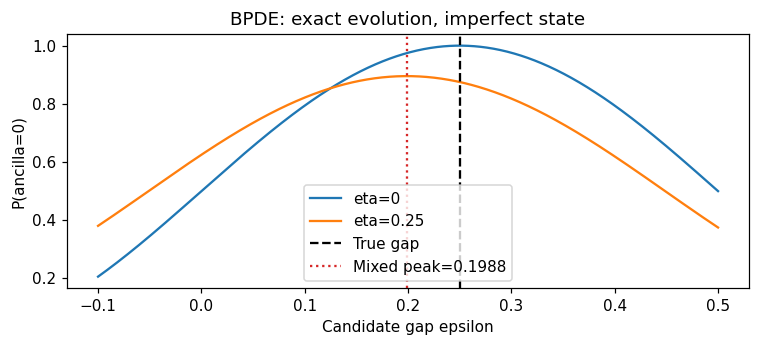

In [15]:
eta = 0.25
peak_b = np.angle(eta + (1-eta)*np.exp(1j*TAU*GAP)) / TAU
candidate = np.linspace(-0.1, 0.5, 1001)
fig, ax = plt.subplots(figsize=(8, 3))
for e in [0, eta]:
    ax.plot(candidate, bpde_probability(e, 1, -TAU*candidate), label=f"eta={e}")
ax.axvline(GAP, color="black", ls="--", label="True gap")
ax.axvline(peak_b, color="C3", ls=":", label=f"Mixed peak={peak_b:.4f}")
ax.set(xlabel="Candidate gap epsilon", ylabel="P(ancilla=0)", title="BPDE: exact evolution, imperfect state")
ax.legend(); plt.show()
print("Exact mixed-input BPDE fringe peak:", peak_b)

post_gap_mixed, _ = bayes_update(GRID, scan_settings,
                                lambda L,b: bpde_probability(eta, L, b), shots=2048, seed=84)
print("単一ギャップモデルの推定:", posterior_summary(GRID, post_gap_mixed[-1]))

### 演習5：差を直接測るとは何か

1. $K$を $K+cI$ へ変えると、BPEとBPDEの位相はどう変わりますか？
2. BPDEなら近似状態の問題が自動的に解消されますか？
3. 本例で $\eta=1$ としたときの信号を予想して、コードで確認してください。

<details><summary>解答例</summary>

1. BPEの位相は $c$ ずれます（mod 1）。BPDEでは両枝の共通位相が消えるので差は不変です。
2. 解消しません。厳密な固有状態なら単一ギャップですが、近似状態では別成分の寄与が残ります。
3. 両枝が同じ $|0\rangle$ を準備するので差0だけになります。
   また $\eta=0$ でも余弦は周期的なので、複数の設定や位相の事前区間が必要です。
</details>

## 6．Fig. 1Cへ：同じ状態準備でも、補助だけでは読めない

Kanno論文のCは、準備した重ね合わせへの**戻り確率**を測ります。
$W|00\rangle=|\Psi\rangle$ とすると
$$P_C(\mathrm{全0})=|\langle00|W^\dagger(P(\beta)\otimes U^L)W|00\rangle|^2
=|\langle\Psi|(P(\beta)\otimes U^L)|\Psi\rangle|^2.$$
この量は、$W$の他の入力への作用によらず、準備された状態だけで決まります。

厳密状態のとき、$W_B$を第5節の準備回路として
$$W_C=W_B\,\mathrm{SWAP}$$
を考えます。右から作用するので実行順はSWAP→H→制御$R_y$。
SWAPは初期の00を変えないため、$W_C|00\rangle=W_B|00\rangle$です。
ところが逆準備の最後にはSWAPがあり、位相の情報が出る量子ビットを交換します。
固有状態準備なら $\delta=2\pi L\Delta+\beta$ として、全体位相を除き
$$|\mathrm{out}_B\rangle=\cos(\delta/2)|00\rangle-i\sin(\delta/2)|10\rangle,$$
$$|\mathrm{out}_C\rangle=\cos(\delta/2)|00\rangle-i\sin(\delta/2)|01\rangle.$$
ここは数式の順序 $|a,s\rangle$ です。Cでは補助が常に0でも、全0確率には干渉が残ります。
**SWAPは論文で使用された回路ではなく、測定の違いを示す説明用の回路です。**

epsilon=-1/4: output probabilities (reported as |a,s>)
B {'00': 0.0, '01': 0.0, '10': 1.0, '11': 0.0}
C {'00': 0.0, '01': 1.0, '10': 0.0, '11': 0.0}


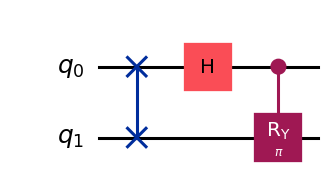

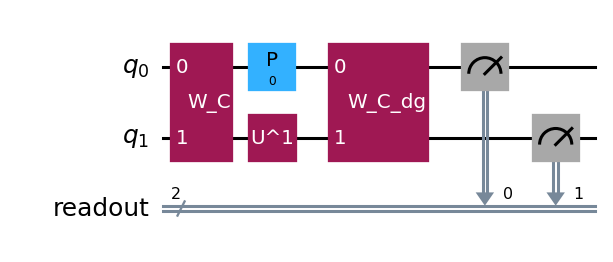

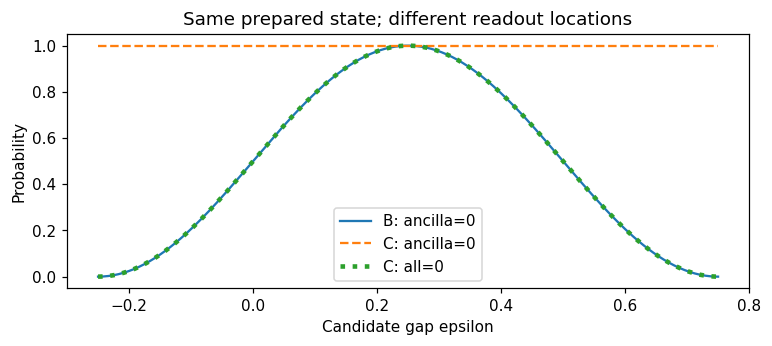

In [16]:
def preparation_c(eta=0.0):
    qc = QuantumCircuit(2, name="W_C")
    qc.swap(0, 1)
    qc.compose(preparation_b(eta), inplace=True)
    return qc

def return_circuit(eta=0.0, L=1, beta=0.0, kind="C"):
    prep = preparation_c(eta) if kind == "C" else preparation_b(eta)
    qc = QuantumCircuit(2)
    qc.append(prep.to_gate(), [0, 1])
    qc.append(UnitaryGate(u_power(L), label=f"U^{L}"), [1])
    qc.p(beta, 0)
    qc.append(prep.inverse().to_gate(), [0, 1])
    return qc

def measurement_probabilities(qc):
    sv = Statevector.from_instruction(qc)
    return float(sv.probabilities([0])[0]), float(abs(sv.data[0])**2)

assert np.allclose(Statevector.from_instruction(preparation_b()).data,
                   Statevector.from_instruction(preparation_c()).data, atol=ATOL)
draw(preparation_c())
draw_measured(return_circuit(), [0, 1])
beta_scan = -TAU*np.linspace(-0.25, 0.75, 241)
curves = {kind: np.array([measurement_probabilities(return_circuit(beta=b, kind=kind))
                           for b in beta_scan]) for kind in ["B", "C"]}
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(-beta_scan/TAU, curves["B"][:, 0], label="B: ancilla=0")
ax.plot(-beta_scan/TAU, curves["C"][:, 0], "--", label="C: ancilla=0")
ax.plot(-beta_scan/TAU, curves["C"][:, 1], ":", lw=3, label="C: all=0")
ax.set(xlabel="Candidate gap epsilon", ylabel="Probability", title="Same prepared state; different readout locations")
ax.legend(); plt.show()
assert np.allclose(curves["C"][:, 0], 1, atol=ATOL)
assert np.allclose(curves["B"][:, 0], curves["C"][:, 1], atol=ATOL)

# delta=pi の設定。Qiskit配列は |s,a> の順で表示されることに注意。
print("epsilon=-1/4: output probabilities (reported as |a,s>)")
for kind in ["B", "C"]:
    state = Statevector.from_instruction(return_circuit(beta=np.pi/2, kind=kind))
    print(kind, {f"{a}{s}": round(float(abs(state.data[2*s+a])**2), 6)
                 for a in [0,1] for s in [0,1]})

### 演習6：逆回路なら元に戻るのでは？

なぜ $W_C$が厳密な準備回路なのに、逆準備後の補助0は正解判定にならないのでしょうか。
$\epsilon=-1/4$ のBとCの出力を使って説明してください。

<details><summary>解答例</summary>

逆回路が00へ戻すと保証されるのは、準備した元の状態そのものです。
時間発展で相対位相が変わった状態の出先は、$W$全体の作用に依存します。
この設定ではBは $|a,s\rangle=|10\rangle$、Cは $|01\rangle$ です。
Cでは元の状態へ戻っていないのに、補助だけは0です。
全0射影はランク1、補助0の射影は $|0\rangle\langle0|\otimes I$ であり、より広い部分空間を成功として数えます。
</details>

### 6.1 全0測定でも、初期状態の誤差は消えない

両枝の状態が $|\widetilde g\rangle,|\widetilde e\rangle$ なら
$$A_j(L)=\langle\widetilde j|U^L|\widetilde j\rangle,\qquad
P_C(\mathrm{全0})=\tfrac14|A_g(L)+e^{i\beta}A_e(L)|^2.$$
固有状態なら $|A_j|=1$ で、単一ギャップの余弦に戻ります。
本例は $A_g=e^{2\pi iL\phi_0}$、
$A_e=\eta e^{2\pi iL\phi_0}+(1-\eta)e^{2\pi iL\phi_1}$ です。
一般には各 $A_j$が複数固有位相の和なので、全0測定でも目的以外の差が信号へ混ざります。

Fig. 1BとCは、厳密状態なら同じ理想信号ですが、近似状態では同じ測定ではありません。
Kanno論文SI S1は目的の2固有状態で近似して単一余弦を導き、Gaussian近似して更新します。
複数の固有値と重みを同時に推定するモデルは、その手順には含まれていません。
状態準備の忠実度は評価されており、「著者が近似誤差を認識していない」という意味ではありません。

この片側だけ近似の例ではピーク位置が同じでも、背景・振幅が違います。


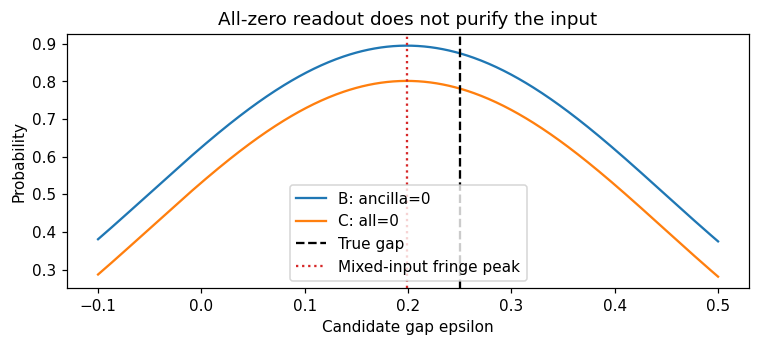

In [17]:
def c_probability(eta, L, beta):
    ag = np.exp(1j*TAU*L*PHASES[0])
    ae = eta*ag + (1-eta)*np.exp(1j*TAU*L*PHASES[1])
    return 0.25 * np.abs(ag + np.exp(1j*beta)*ae)**2

for eta in [0, 0.25, 0.7]:
    for L in [1, 2, 5]:
        for beta in [0, 0.31, -1.7]:
            for kind in ["B", "C"]:
                _, all0 = measurement_probabilities(return_circuit(eta, L, beta, kind))
                assert np.isclose(all0, c_probability(eta, L, beta), atol=ATOL)

eta = 0.25
eps = np.linspace(-0.1, 0.5, 501)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(eps, bpde_probability(eta, 1, -TAU*eps), label="B: ancilla=0")
ax.plot(eps, c_probability(eta, 1, -TAU*eps), label="C: all=0")
ax.axvline(GAP, color="black", ls="--", label="True gap")
ax.axvline(peak_b, color="C3", ls=":", label="Mixed-input fringe peak")
ax.set(xlabel="Candidate gap epsilon", ylabel="Probability", title="All-zero readout does not purify the input")
ax.legend(); plt.show()
print("この片側だけ近似の例ではピーク位置が同じでも、背景・振幅が違います。")

## 7．全0測定のメリット：脱分極背景を拾いにくい

Kanno論文SI S5では、**測定直前の全体脱分極**を仮定します。補助を含めて $n$ 量子ビットとして
$$\rho_{\rm noisy}=(1-p)\rho+p\frac{I}{2^n}.$$
任意の射影 $\Pi$ に対し
$$\operatorname{Tr}(\Pi\rho_{\rm noisy})
=(1-p)\operatorname{Tr}(\Pi\rho)+p\frac{\operatorname{rank}\Pi}{2^n}.$$
補助0はランク $2^{n-1}$、全0はランク1なので、理想信号を $f(\epsilon)$ とすると
$$P_{a=0}=(1-p)f(\epsilon)+p/2,\qquad
P_{\rm all0}=(1-p)f(\epsilon)+p/2^n.$$
**指数的に減るのは加算的な背景 $p/2^n$ です。信号の減衰 $(1-p)$ は残ります。**
同じ $p$ で比較しており、量子ビットやゲートが増えても $p$ が一定になるという保証ではありません。
局所ゲートノイズ・読み出し誤り一般が、このモデルに厳密に従うわけでもありません。

以下の2ビット例では実際に密度行列を作り、両測定のトレースを計算します。
この比較にはB回路の同じ出力を使います。**Bでも全ビットを測れば同じ背景抑制を得られる**ためです。

2-qubit density matrix: ancilla=0 0.5499999999999999 all=0 0.32499999999999996
固定pでの理論値。大きいnの回路を実行した結果ではありません。
n= 2: background=2.250e-01, expected background counts / 10000 shots=2.250e+03
n= 9: background=1.758e-03, expected background counts / 10000 shots=1.758e+01
n=21: background=4.292e-07, expected background counts / 10000 shots=4.292e-03
n=33: background=1.048e-10, expected background counts / 10000 shots=1.048e-06


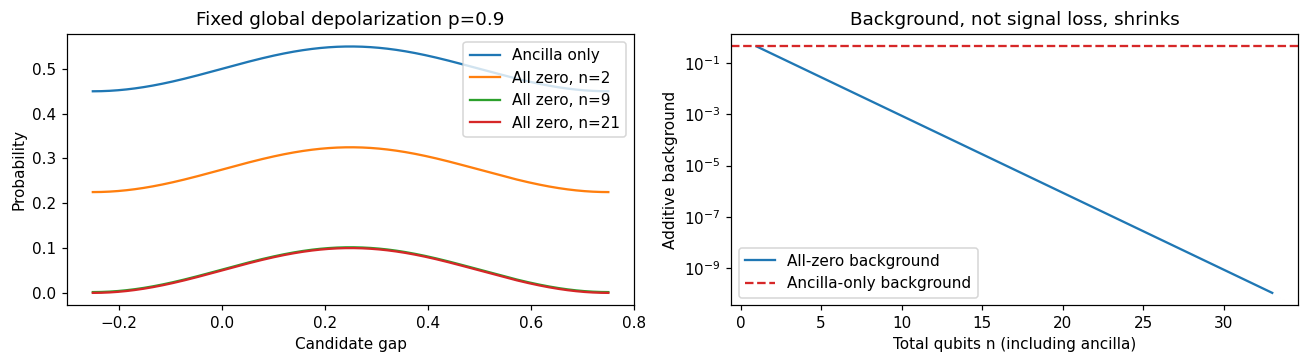

In [18]:
p_dep = 0.9
qc = bpde_circuit(eta=0, L=1, beta=-TAU*GAP)
rho = DensityMatrix(Statevector.from_instruction(qc)).data
noisy = (1-p_dep)*rho + p_dep*np.eye(4)/4
# Qiskitの並びは |s,a>。a=0は添字0,2。
pi_anc0 = np.diag([1, 0, 1, 0])
pi_all0 = np.diag([1, 0, 0, 0])
actual_anc = np.trace(pi_anc0 @ noisy).real
actual_all = np.trace(pi_all0 @ noisy).real
print("2-qubit density matrix: ancilla=0", actual_anc, "all=0", actual_all)
assert np.isclose(actual_anc, (1-p_dep)+p_dep/2, atol=ATOL)
assert np.isclose(actual_all, (1-p_dep)+p_dep/4, atol=ATOL)

eps = np.linspace(-0.25, 0.75, 801)
ideal = 0.5*(1+np.cos(TAU*(GAP-eps)))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(eps, (1-p_dep)*ideal+p_dep/2, label="Ancilla only")
for n in [2, 9, 21]:
    axes[0].plot(eps, (1-p_dep)*ideal+p_dep/2**n, label=f"All zero, n={n}")
axes[0].set(xlabel="Candidate gap", ylabel="Probability", title=f"Fixed global depolarization p={p_dep}")
axes[0].legend()
ns = np.arange(1, 34)
axes[1].semilogy(ns, p_dep/2**ns, label="All-zero background")
axes[1].axhline(p_dep/2, color="C3", ls="--", label="Ancilla-only background")
axes[1].set(xlabel="Total qubits n (including ancilla)", ylabel="Additive background", title="Background, not signal loss, shrinks")
axes[1].legend(); plt.tight_layout(); plt.show()

shots = 10000
print("固定pでの理論値。大きいnの回路を実行した結果ではありません。")
for n in [2, 9, 21, 33]:
    print(f"n={n:2}: background={p_dep/2**n:.3e}, "
          f"expected background counts / {shots} shots={shots*p_dep/2**n:.3e}")

### 演習7：量子ビットを増やせばノイズが消える？

1. $p=1$ なら、背景が小さくてもギャップを推定できますか？
2. $p=0.9999$、10,000 shotsでの信号成分の期待カウントは最大いくつですか？
3. 本物のC回路で補助だけ測ることと、B回路で全0測定へ変更することは同じですか？

<details><summary>解答例</summary>

1. できません。確率が候補値に依存せず、情報がありません。
2. ピークで $R(1-p)=1$ countです。背景が消えても、有限shotで情報を得られるとは限りません。
3. 同じではありません。Cの一般の逆準備では位相情報が補助へ出る保証がないからです。
   一方、Bに全0判定を追加することは可能で、厳密固有状態では理想の補助信号を保ちつつ同じ脱分極背景抑制を得られます。
</details>

## 8．発展：3桁で表せない位相に変える

ここまでのQPE/IQPEの完全なビット列は、位相が3桁で表せる特別な条件でした。
一般の位相でのQPE出力確率は
$$P(y\mid\phi)=\left|\frac1M\sum_{x=0}^{M-1}e^{2\pi ix(\phi-y/M)}\right|^2,\qquad M=2^m.$$
入力が複数固有状態なら、この分布を重なりの二乗で混ぜたものになります。
以下では $\phi_0=0.14,\phi_1=0.37$ として、2,3,6個の補助を比較します。
同じKraus計算によるIQPEもQPEと照合します。有限分解能では条件付き系が厳密固有状態になるとも限りません。

非格子位相でも、全回路QPE・独立な解析式・条件付きIQPEの分布が一致しました。


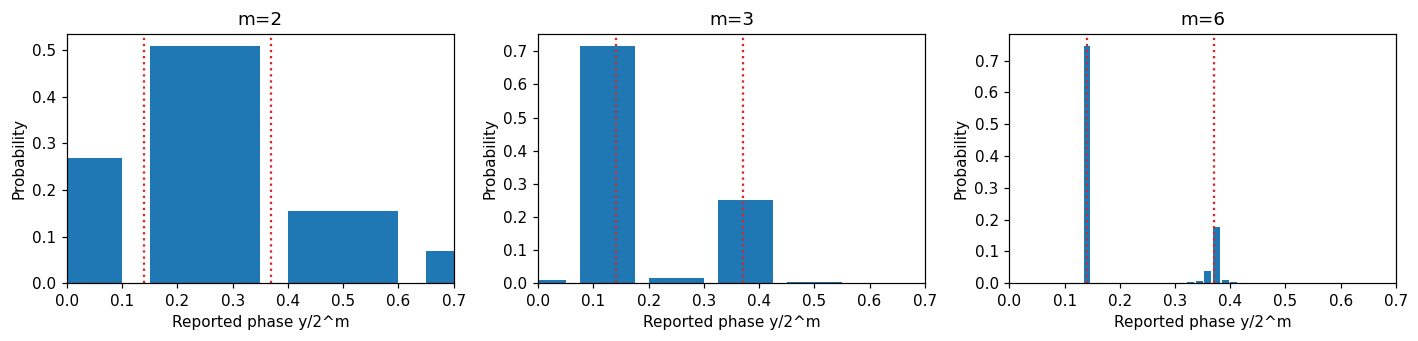

In [19]:
offgrid = np.array([0.14, 0.37])

def qpe_formula(phi, m):
    M = 2**m
    d = phi - np.arange(M)/M
    amplitudes = np.mean(np.exp(1j*TAU*np.outer(np.arange(M), d)), axis=0)
    return abs(amplitudes)**2

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, m in zip(axes, [2, 3, 6]):
    p = qpe_distribution(psi_mixed, m, offgrid)
    analytical = sum(w*qpe_formula(phi, m) for w, phi in zip(abs(psi_mixed)**2, offgrid))
    iterative, _ = iqpe_tree(psi_mixed, m, offgrid)
    assert np.allclose(p, analytical, atol=ATOL)
    assert np.allclose(p, iterative, atol=ATOL)
    ax.bar(np.arange(2**m)/2**m, p, width=0.8/2**m)
    for phi in offgrid:
        ax.axvline(phi, color="C3", ls=":")
    ax.set(xlabel="Reported phase y/2^m", ylabel="Probability", title=f"m={m}", xlim=(0, 0.7))
plt.tight_layout(); plt.show()
print("非格子位相でも、全回路QPE・独立な解析式・条件付きIQPEの分布が一致しました。")

### 演習8：3種類の誤差を分類する

次の現象を、有限ビット分解能／shot誤差／初期状態と推定モデルの不一致に分けてください。

- 厳密固有状態0.14を3ビットQPEに入れても、出力が1つのビット列にならない。
- 同じ設定でも、1,000 shotsの0の回数が実行ごとに違う。
- 近似状態の厳密な干渉確率のピークが0.1762になる。

<details><summary>解答例</summary>

順に、有限ビット分解能、shot誤差、初期状態と単一位相モデルの不一致です。
加えて実機では状態準備・時間発展のゲート誤差や読み出し誤りがあり、別に評価する必要があります。
</details>

## 9．4方式とFig. 1Cを自分の言葉で説明する

| 方式 | 系に加える補助 | 推定途中の系 | 理想的な出力・信号 |
|---|---:|---|---|
| 逆QFT型QPE | $m$ 個 | 全回路中保持 | $m$ ビットの位相。入力重みが固有位相ごとの確率へ |
| iterative QPE | 1個 | **各ビット後も条件付き状態を保持** | 同じ分布を下位ビットから逐次読出し |
| この教材のBPE | 1個 | 毎ショット再準備 | エネルギー位相の干渉を古典推定 |
| Fig. 1B型BPDE | 1個 | 毎ショット再準備 | 枝別準備・制御なし時間発展・補助測定 |
| Fig. 1C型の戻り測定 | 1個 | 毎ショット再準備 | 準備した重ね合わせへの戻りを全0測定 |

この表のBPE・BPDEは本教材の実装条件です。ベイズ推定全般をこの分類だけで定義するものではありません。
また、QPE/IQPEで正しい固有位相を得ても、目的状態を十分な確率で得るには非零で十分な重なりが必要です。

### 資源を公平に比べるには

$m=3$のQPE/IQPEは1回の3ビット読出しに $U^1,U^2,U^4$ を使い、$U$換算7回です。
IQPEでは途中測定と古典フィードバックが必要で、系のコヒーレンスを保持します。
BPE/BPDEは設定数・shotsに加え、$\sum_{\rm settings}RL$、最大の $L$、準備と逆準備の回数も数えてください。
制御Uと制御なしUの実装コストは同じとは限りません。
本教材のshot数は分布を見やすくするための例であり、同精度・同成功確率での最適資源比較ではありません。

### 最終演習

1. 「補助1個なら、iterative QPEとBPEは同じ」と言えない理由を説明してください。
2. ノイズなし・厳密時間発展なら、BPE/BPDEは任意の初期状態から厳密な目的固有値を必ず得ますか？
3. Cの全0測定が初期状態の混合を消す、という説明のどこが誤りですか？
4. Kanno論文Fig. 1A→B→Cを、それぞれ何を比較して何を測定するかで説明してください。
5. 「ノイズ効果が量子ビット数に対して指数的に抑制される」を、条件と対象を含めて正確に言い換えてください。

<details><summary>解答例</summary>

1. 本教材のIQPEは同じ系の条件付き状態を保持し、BPEは再準備した多数の系から得たデータを推定します。
2. 保証されません。近似状態による複数成分の信号と単一位相モデルが不一致になり得ます。
   混合データでも条件によって正しい値を得ることはあり、「必ず不正確」という意味でもありません。
3. 全0は準備した**近似状態**への戻りです。厳密な目的固有状態への射影とは異なります。
4. Aは非発展枝と発展枝、Bは基底側と励起側の枝を比較し補助を測定します。
   Cは同じ重ね合わせ干渉を一般の準備回路で実現し、準備状態への戻りを全0測定します。
   本教材のCはその読出し原理のみで、論文のMPO圧縮の再現ではありません。
5. 測定前の全体脱分極率を固定すると、全0確率への加算背景は $p/2^n$ になる、です。
   信号減衰、必要shot数、局所誤りや読み出し誤り一般まで指数的に改善するという主張ではありません。
</details>

## 10．参考資料と教材の範囲

- M. Dobšíček et al., *Arbitrary accuracy iterative quantum phase estimation algorithm using a single ancillary qubit: A two-qubit benchmark*, PRA 76, 030306(R) (2007).
  [原著](https://arxiv.org/abs/quant-ph/0610214)：補助1個によるiterative QPE。
- N. Wiebe and C. Granade, *Efficient Bayesian Phase Estimation*, PRL 117, 010503 (2016).
  [原著](https://arxiv.org/abs/1508.00869)：効率的な適応的BPE。本教材はグリッド法による説明用実装。
- K. Sugisaki, *Projective Measurement-Based Quantum Phase Difference Estimation Algorithm for the Direct Computation of Eigenenergy Differences on a Quantum Computer*, JCTC (2023).
  [出版版](https://doi.org/10.1021/acs.jctc.3c00784) /
  [arXiv版](https://arxiv.org/abs/2307.09825)：IntroductionとBPE/BPDEの初期状態依存。
  **本教材は同論文の逆QFT型QPDEを実装・検証するものではありません。**
- S. Kanno et al., *Tensor-based quantum phase difference estimation for large-scale demonstration*, PNAS 122, e2425026122 (2025).
  [出版版](https://doi.org/10.1073/pnas.2425026122) /
  [本文・SIのHTML版](https://arxiv.org/html/2408.04946v4)：Fig. 1、SI S1の推定式、SI S5の脱分極モデル。
- [Qiskit Statevector公式API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector)：回路からの状態ベクトルと部分レジスタの確率計算。

本教材独自の行列・回路・数値例です。回路図はコードから生成しています。
全0測定のSWAP例、グリッド推定、固定測定設定は原著の実機回路・推定アルゴリズムそのものではありません。
厳密確率の計算は小規模状態ベクトル・密度行列を使うため、量子優位性の実証ではありません。

In [20]:
# 最後の確認：期待する厳密値・別の実装同士の照合。
assert np.allclose(p_qpe, expected, atol=ATOL)
assert np.allclose(p_iqpe, expected, atol=ATOL)
assert np.isclose(peak_a, 0.17620819117478337, atol=ATOL)
assert np.isclose(peak_b, 0.19879180882521663, atol=ATOL)
assert abs(posterior_summary(GRID, post_exact[-1])["MAP"] - PHASES[0]) < 0.005
assert abs(posterior_summary(GRID, post_gap[-1])["MAP"] - GAP) < 0.005
print("全セル完了。QFT行列・回路と解析式・QPEとIQPE・密度行列とノイズ式を照合しました。")

全セル完了。QFT行列・回路と解析式・QPEとIQPE・密度行列とノイズ式を照合しました。
